# Mining comparison on AIT-ADS (plan 7.6, temporal arm)

Same question as notebook 06 (does the mining principle matter?), now on data with an alert order to mine, so all
five methods run:

|  | Label used **after** the search | Label used **during** the search |
|---|---|---|
| **Atemporal** | Eclat | Contrast tree (ours), RIPPER |
| **Temporal** | PrefixSpan | MCTSExtent |

**Protocol: within-scenario 70/30 split (the thesis setup, decided 2026-11-21).** Per scenario, its labelled groups
(cscas_grouping, token arm T2) in time order: the first 70% train, the last 30% test (as in
`baselines/_ait_ads_data.py`, thesis Table 5.9). Scenarios with no attack in their first 70% are skipped (harrison,
russellmitchell, santos), leaving 5 steps. Same kind of test as the CSCAS walk-forward: train on the past of the same
network. (The earlier leave-one-scenario-out runs are a harder, different test; set `PROTOCOL = "loso"` below to
reopen them.) Temporal methods mine per-host look-back
sequences (10 min, 1-min buckets). Same shared treatment as CSCAS: precision gate (benign side relaxed to ≤ π),
condition + near-duplicate dedupe, budget K = 60 per class, class-weighted RF at 0.5, 5 seeds (RIPPER and
MCTSExtent re-mined per seed).

**Testing with 5 steps.** Across 5 scenarios, a Wilcoxon test can't go below p = 0.0625 even when one method wins all
5, and the Friedman / Nemenyi test has little power. The main test here is a **paired bootstrap over the test groups**
within each scenario (§5; `bootstrap.csv`, `thesis.system_eval.score_bootstrap`): 1000 resamples of the test groups,
stratified by class, both arms scored on the same resample, each arm averaged over its seeds; plus the mean over the
scenarios ("all"). A difference is significant when its 95% interval excludes 0 (p not corrected for the number of
pairs).

**Read with the label noise in mind.** AIT-ADS labels everything inside an attack time window as an attack, so
F1 and precision stay low for every arm (FINDINGS.md). Compare on PR-AUC and the helps/hurts counts.

Logic: `thesis.system_eval.mining_comparison`; run with `shell-scripts/paper/run_mining_comparison_ait_ads.sh` (DGX).

In [1]:
from __future__ import annotations

import json
import re
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sps

from thesis.paths import ROOT
from thesis.system_eval import mining_comparison as mc

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

ARMS = ["mctsextent", "prefixspan", "ripper", "contrast_tree", "eclat", "none"]
METHODS = [a for a in ARMS if a != "none"]
LABEL = {"mctsextent": "MCTSExtent", "prefixspan": "PrefixSpan", "ripper": "RIPPER",
         "contrast_tree": "Contrast tree", "eclat": "Eclat", "none": "No mining"}
COLOR = {"mctsextent": "tab:purple", "prefixspan": "tab:red", "ripper": "tab:green",
         "contrast_tree": "tab:blue", "eclat": "tab:orange", "none": "tab:gray"}


def to_booktabs(df: pd.DataFrame, caption: str, label: str, float_fmt: str = "{:.3f}") -> str:
    styler = df.style.hide(axis="index").format(
        {c: float_fmt for c in df.select_dtypes("float").columns}
    ).format_index(escape="latex", axis=1).format(escape="latex-math", subset=df.select_dtypes("object").columns)
    return styler.to_latex(hrules=True, caption=caption, label=label, position="t", position_float="centering")

## Load

In [2]:
PROTOCOL = "split"  # "split" (main) | "loso" (the earlier leave-one-scenario-out runs)
RUN_DIR = None  # None -> latest finished run of PROTOCOL with the most scenarios, else a path

BASE = {"split": "mining_comparison_ait_ads_split", "loso": "mining_comparison_ait_ads"}[PROTOCOL]


def _latest_full_run() -> Path:
    base = ROOT / "artifacts" / "experiments" / BASE
    runs = [d for d in sorted(base.glob("*")) if (d / "summary.csv").exists()]
    if not runs:
        raise FileNotFoundError(f"no finished run under {base}")
    n_steps = {d: pd.read_csv(d / "per_step_results.csv")["scenario"].nunique() for d in runs}
    best = max(n_steps.values())
    return [d for d in runs if n_steps[d] == best][-1]


run_dir = Path(RUN_DIR) if RUN_DIR else _latest_full_run()
per_step = pd.read_csv(run_dir / "per_step_results.csv")
features = pd.read_csv(run_dir / "features.csv")
windows = pd.read_csv(run_dir / "windows.csv")
skipped = pd.read_csv(run_dir / "skipped.csv") if (run_dir / "skipped.csv").exists() else pd.DataFrame()
boot = pd.read_csv(run_dir / "bootstrap.csv") if (run_dir / "bootstrap.csv").exists() else None
means = mc.per_step_means(per_step)  # seed-averaged, one row per (arm, scenario step)
FOLD = per_step.groupby("step_i")["scenario"].first().rename("scenario")  # step_i -> scenario
N = len(FOLD)
print(run_dir)
print("scenarios:", list(FOLD), "| skipped:", list(skipped.get("scenario", [])),
      "| rows per arm:", per_step.groupby("arm").size().to_dict(), "| seeds:", sorted(per_step["seed"].unique()))


/Users/annavisman/stack/TUDelft/thesis/msc-thesis/artifacts/experiments/mining_comparison_ait_ads_split/20261121_163159
scenarios: ['fox', 'shaw', 'wardbeck', 'wheeler', 'wilson'] | skipped: ['harrison', 'russellmitchell', 'santos'] | rows per arm: {'contrast_tree': 25, 'eclat': 25, 'mctsextent': 25, 'none': 25, 'prefixspan': 25, 'ripper': 25} | seeds: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


### The scenarios

Each step trains on a scenario's first 70% and tests on its last 30%. Skipped scenarios have no attack to learn from
in their training part (all their attacks fall in the last 30%).

In [3]:
folds = windows.assign(test_attack_rate=windows["n_test_attack"] / windows["n_test"])[
    ["scenario", "n_train", "n_train_attack", "n_test", "n_test_attack", "test_attack_rate", "test_days"]
]
display(folds.round(3))
if not skipped.empty:
    display(skipped[["scenario", "n_train", "n_train_attack", "n_test", "n_test_attack", "reason"]])

,scenario,n_train,n_train_attack,n_test,n_test_attack,test_attack_rate,test_days
0,fox,4264,109,1828,157,0.086,1.485
1,shaw,4465,17,1914,77,0.040,1.466
2,wardbeck,5651,14,2423,147,0.061,1.562
3,wheeler,12447,49,5335,182,0.034,1.351
4,wilson,10605,153,4545,280,0.062,1.701


,scenario,n_train,n_train_attack,n_test,n_test_attack,reason
0,harrison,11203,0,4802,727,no training attacks
1,russellmitchell,3150,0,1350,198,no training attacks
2,santos,7730,0,3313,231,no training attacks


## §1 Main table

Mean (± std over scenarios) of the seed-averaged metrics. `mine_seconds` is the whole mine → gate → dedupe step per
seed (the miner alone: `miner_seconds`). Redundancy = share of gated distinct conditions dropped as
near-duplicates. Means over 5 scenarios, of which only fox and wilson carry signal (§2), so read the per-scenario table first.

In [4]:
summary = mc.summarize_comparison(per_step).set_index("arm")
main = pd.DataFrame({
    "PR-AUC": summary["pr_auc_mean"], "PR-AUC sd": summary["pr_auc_std"],
    "F1": summary["f1_mean"], "Precision": summary["precision_mean"], "Recall": summary["recall_mean"],
    "ROC-AUC": summary["auc_mean"], "FP/day": summary["fp_per_day_mean"],
    "Features": summary["n_symbolic_mean"], "Cond./feat.": summary["mean_conditions_mean"],
    "Overlap": summary["overlap_mean"], "Redundancy": summary["redundancy_share_mean"],
    "Mine s": summary["mine_seconds_mean"],
}).reindex(ARMS)
main

,PR-AUC,PR-AUC sd,F1,Precision,Recall,ROC-AUC,FP/day,Features,Cond./feat.,Overlap,Redundancy,Mine s
arm,,,,,,,,,,,,
mctsextent,0.175448,0.162886,0.107559,0.138601,0.091744,0.650614,32.266713,39.96,3.123952,0.163932,0.000000,76.4048
prefixspan,0.135847,0.124664,0.098808,0.123854,0.082595,0.614360,43.251494,38.40,2.742602,0.267403,0.968566,5.4340
ripper,0.143308,0.137088,0.140438,0.124542,0.161923,0.618013,75.179501,3.96,2.248223,0.014713,0.000000,1.6256
contrast_tree,0.150612,0.148170,0.156087,0.135668,0.183776,0.629424,70.991815,22.40,2.005512,0.080891,0.620102,0.4080
eclat,0.153773,0.149616,0.143236,0.130865,0.158249,0.628693,66.944531,19.00,3.175554,0.083576,0.900330,0.5840
none,0.154381,0.151028,0.152781,0.129247,0.187345,0.628821,84.595990,0.00,NaN,NaN,NaN,NaN


In [5]:
latex_main = main.reset_index().rename(columns={"arm": "Method"}).assign(Method=lambda d: d["Method"].map(LABEL))
print(to_booktabs(
    latex_main[["Method", "PR-AUC", "F1", "Precision", "Recall", "FP/day", "Features", "Cond./feat.",
                "Redundancy", "Mine s"]],
    caption=f"Mining comparison on AIT-ADS: within-scenario 70/30 split, means over {N} scenarios and 5 seeds "
            "(K = 60, class-weighted RF).",
    label="tab:mining-comparison-ait-ads",
))

\begin{table}[t]
\centering
\caption{Mining comparison on AIT-ADS: within-scenario 70/30 split, means over 5 scenarios and 5 seeds (K = 60, class-weighted RF).}
\label{tab:mining-comparison-ait-ads}
\begin{tabular}{lrrrrrrrrr}
\toprule
Method & PR-AUC & F1 & Precision & Recall & FP/day & Features & Cond./feat. & Redundancy & Mine s \\
\midrule
MCTSExtent & 0.175 & 0.108 & 0.139 & 0.092 & 32.267 & 39.960 & 3.124 & 0.000 & 76.405 \\
PrefixSpan & 0.136 & 0.099 & 0.124 & 0.083 & 43.251 & 38.400 & 2.743 & 0.969 & 5.434 \\
RIPPER & 0.143 & 0.140 & 0.125 & 0.162 & 75.180 & 3.960 & 2.248 & 0.000 & 1.626 \\
Contrast tree & 0.151 & 0.156 & 0.136 & 0.184 & 70.992 & 22.400 & 2.006 & 0.620 & 0.408 \\
Eclat & 0.154 & 0.143 & 0.131 & 0.158 & 66.945 & 19.000 & 3.176 & 0.900 & 0.584 \\
No mining & 0.154 & 0.153 & 0.129 & 0.187 & 84.596 & 0.000 & nan & nan & nan \\
\bottomrule
\end{tabular}
\end{table}



## §2 Per scenario

Seed-averaged PR-AUC and F1 per scenario, and the gain over `none`. A scenario carries signal only if `none` (or
any arm) beats chance: PR-AUC above the test attack rate, F1 above 0. Helps/hurts counts as in notebook 06.

In [6]:
pr = means.pivot(index="step_i", columns="arm", values="pr_auc").rename(index=FOLD)[ARMS]
pr.index.name, pr.columns.name = "scenario", None
display(pr.round(3))
f1 = means.pivot(index="step_i", columns="arm", values="f1").rename(index=FOLD)[ARMS]
f1.index.name, f1.columns.name = "scenario", None
display(f1.round(3))

# Chance level: PR-AUC of a random score is the test attack rate; F1 = 0 means no attack was flagged.
signal = pd.DataFrame({
    "test attack rate": folds.set_index("scenario")["test_attack_rate"],
    "best PR-AUC": pr.max(axis=1),
    "best F1": f1.max(axis=1),
})
signal["carries signal"] = (signal["best F1"] > 0) | (signal["best PR-AUC"] > 1.5 * signal["test attack rate"])
signal.round(3)

,mctsextent,prefixspan,ripper,contrast_tree,eclat,none
scenario,,,,,,
fox,0.384,0.292,0.258,0.267,0.307,0.296
shaw,0.080,0.040,0.040,0.040,0.040,0.040
wardbeck,0.061,0.061,0.061,0.061,0.061,0.061
wheeler,0.035,0.036,0.034,0.034,0.034,0.034
wilson,0.318,0.250,0.324,0.352,0.327,0.341


,mctsextent,prefixspan,ripper,contrast_tree,eclat,none
scenario,,,,,,
fox,0.348,0.213,0.278,0.336,0.312,0.315
shaw,0.000,0.000,0.000,0.000,0.000,0.000
wardbeck,0.000,0.000,0.000,0.000,0.000,0.000
wheeler,0.000,0.000,0.000,0.000,0.000,0.000
wilson,0.190,0.281,0.424,0.444,0.404,0.448


,test attack rate,best PR-AUC,best F1,carries signal
scenario,,,,
fox,0.086,0.384,0.348,True
shaw,0.040,0.080,0.000,True
wardbeck,0.061,0.061,0.000,False
wheeler,0.034,0.036,0.000,False
wilson,0.062,0.352,0.448,True


In [7]:
hh = pd.concat([mc.helps_hurts(per_step, m) for m in ("pr_auc", "f1")], ignore_index=True)
hh

,arm,metric,n_steps,mean_delta,median_delta,helps,hurts,ties
0,contrast_tree,pr_auc,5,-0.003769,-0.000032,1,3,1
1,eclat,pr_auc,5,-0.000608,-0.000008,1,3,1
2,mctsextent,pr_auc,5,0.021067,0.000550,3,1,1
3,prefixspan,pr_auc,5,-0.018534,0.000000,1,2,2
4,ripper,pr_auc,5,-0.011073,-0.000069,1,3,1
5,contrast_tree,f1,5,0.003306,0.000000,1,1,3
6,eclat,f1,5,-0.009545,0.000000,0,2,3
7,mctsextent,f1,5,-0.045222,0.000000,1,1,3
8,prefixspan,f1,5,-0.053973,0.000000,0,2,3
9,ripper,f1,5,-0.012343,0.000000,0,2,3


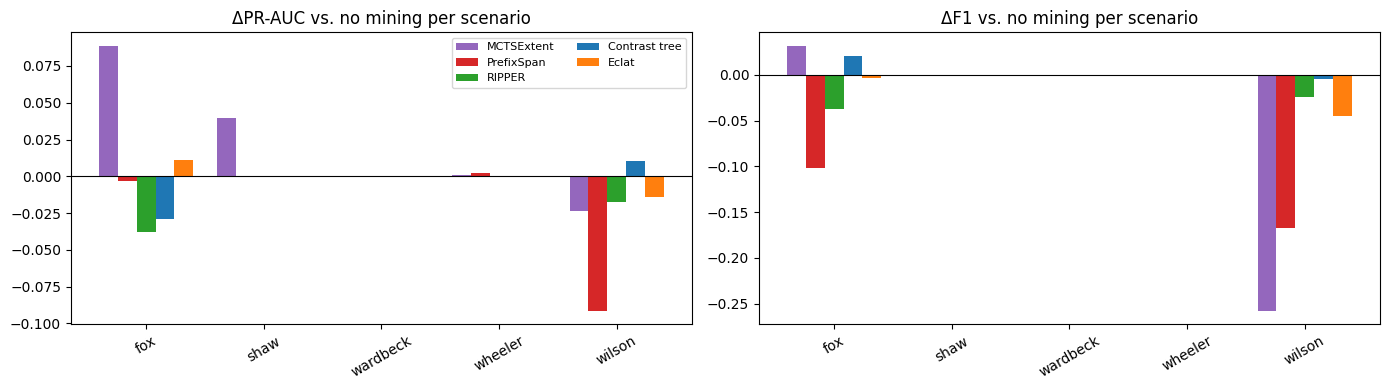

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(pr))
w = 0.16
for ax, m in zip(axes, ("pr_auc", "f1")):
    d = means.pivot(index="step_i", columns="arm", values=m).rename(index=FOLD)
    for j, a in enumerate(METHODS):
        ax.bar(x + (j - 2) * w, d[a] - d["none"], width=w, color=COLOR[a], label=LABEL[a])
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xticks(x, d.index, rotation=30)
    ax.set_title(f"Δ{m.upper().replace('_', '-')} vs. no mining per scenario")
axes[0].legend(fontsize=8, ncol=2)
plt.tight_layout()

## §3 Friedman test + Nemenyi critical difference

Scenarios are the blocks (seed-averaged). Rank 1 = best. With 6 arms and 5 scenarios the CD is very large (~3.4
ranks) and the three scenarios at chance tie every arm, so this has almost no power: shown for completeness, the
bootstrap (§5) is the test.

In [9]:
stats = {m: mc.friedman_nemenyi(per_step, m) for m in ("pr_auc", "f1")}
pd.DataFrame([{"metric": s["metric"], "chi2": s["friedman_chi2"], "p": s["friedman_p"], "CD": s["nemenyi_cd"],
               **{LABEL[a]: r for a, r in s["avg_rank"].items()}} for s in stats.values()])

,metric,chi2,p,CD,MCTSExtent,No mining,PrefixSpan,Eclat,Contrast tree,RIPPER
0,pr_auc,3.633094,0.603351,3.371817,2.5,3.0,3.6,3.7,4.1,4.1
1,f1,5.142857,0.398696,3.371817,3.5,2.9,4.3,3.7,2.9,3.7


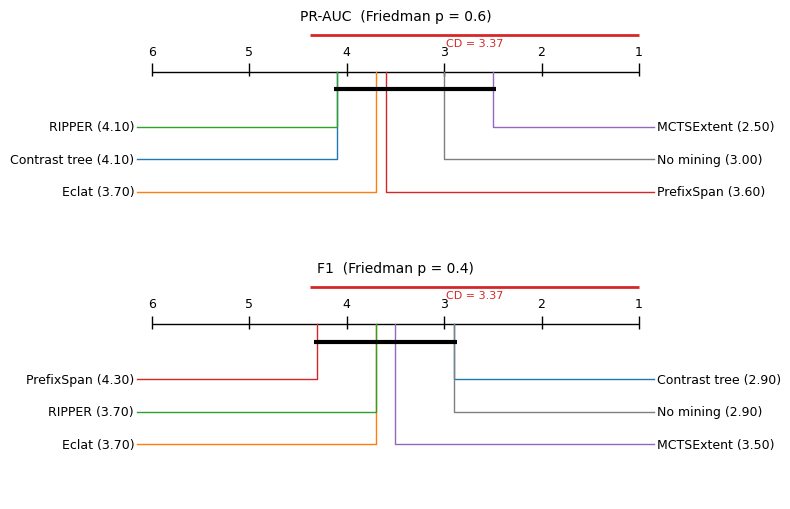

In [10]:
def cd_cliques(ranks: dict[str, float], cd: float) -> list[list[str]]:
    # Maximal groups of arms (in rank order) whose rank span is below CD.
    order = sorted(ranks, key=ranks.get)
    cliques = []
    for i in range(len(order)):
        j = i
        while j + 1 < len(order) and ranks[order[j + 1]] - ranks[order[i]] < cd:
            j += 1
        grp = order[i:j + 1]
        if len(grp) > 1 and not any(set(grp) <= set(c) for c in cliques):
            cliques.append(grp)
    return cliques


def cd_diagram(s: dict, ax) -> None:
    ranks, cd, k = s["avg_rank"], s["nemenyi_cd"], s["n_arms"]
    ax.set_xlim(k + 0.2, 0.8)  # rank 1 on the right
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.hlines(0.8, 1, k, color="k", lw=1)
    for r in range(1, k + 1):
        ax.vlines(r, 0.78, 0.84, color="k", lw=1)
        ax.text(r, 0.88, str(r), ha="center", fontsize=9)
    ax.hlines(0.97, 1, 1 + cd, color="tab:red", lw=2)
    ax.text(1 + cd / 2, 0.92, f"CD = {cd:.2f}", ha="center", fontsize=8, color="tab:red")
    order = sorted(ranks, key=ranks.get)
    half = (len(order) + 1) // 2
    for i, a in enumerate(order):
        right = i < half  # best arms labelled on the right
        y = 0.55 - 0.15 * (i if right else len(order) - 1 - i)
        xe = 0.85 if right else k + 0.15
        ax.plot([ranks[a], ranks[a], xe], [0.8, y, y], color=COLOR[a], lw=1)
        ax.text(xe + (-0.03 if right else 0.03), y, f"{LABEL[a]} ({ranks[a]:.2f})", va="center",
                ha="left" if right else "right", fontsize=9)
    for n, grp in enumerate(cd_cliques(ranks, cd)):
        lo, hi = min(ranks[a] for a in grp), max(ranks[a] for a in grp)
        ax.hlines(0.72 - 0.05 * n, lo - 0.03, hi + 0.03, color="k", lw=3)
    ax.set_title(f"{s['metric'].upper().replace('_', '-')}  (Friedman p = {s['friedman_p']:.2g})", fontsize=10)



fig, axes = plt.subplots(2, 1, figsize=(8, 5.2))
for ax, s in zip(axes, stats.values()):
    cd_diagram(s, ax)
plt.tight_layout()

## §4 The paper's contrasts, paired over scenarios

Paired over the scenarios (seed-averaged): mean Δ (B − A), scenarios where B beats A, and a Wilcoxon signed-rank
p-value. With 5 scenarios the smallest possible Wilcoxon p is 0.0625, so none can be significant; §5 tests the same
contrasts with the bootstrap.

- **Label after vs. during the search:** Eclat → contrast tree (atemporal), PrefixSpan → MCTSExtent (temporal).
- **Two-step patterns vs. learning a rule set directly:** contrast tree → RIPPER.
- **Atemporal vs. temporal** (both frequency-based, only order differs): Eclat → PrefixSpan.

In [11]:
CONTRASTS = [
    ("label after → during (atemporal)", "eclat", "contrast_tree"),
    ("label after → during (temporal)", "prefixspan", "mctsextent"),
    ("two-step → rule set", "contrast_tree", "ripper"),
    ("atemporal → temporal", "eclat", "prefixspan"),
]


def paired(metric: str) -> pd.DataFrame:
    d = means.pivot(index="step_i", columns="arm", values=metric)
    rows = []
    for name, a, b in CONTRASTS:
        diff = d[b] - d[a]
        rows.append({
            "contrast": name, "A": LABEL[a], "B": LABEL[b], "metric": metric,
            "mean A": d[a].mean(), "mean B": d[b].mean(), "mean Δ (B−A)": diff.mean(),
            "B better (scenarios)": f"{int((diff > 0).sum())}/{len(diff)}",
            "Wilcoxon p": sps.wilcoxon(d[b], d[a]).pvalue if (diff != 0).any() else np.nan,
        })
    return pd.DataFrame(rows)


contrasts = pd.concat([paired("pr_auc"), paired("f1")], ignore_index=True)
contrasts.round(4)

,contrast,A,B,metric,mean A,mean B,mean Δ (B−A),B better (scenarios),Wilcoxon p
0,label after → during (atemporal),Eclat,Contrast tree,pr_auc,0.1538,0.1506,-0.0032,2/5,1.000
1,label after → during (temporal),PrefixSpan,MCTSExtent,pr_auc,0.1358,0.1754,0.0396,3/5,0.250
2,two-step → rule set,Contrast tree,RIPPER,pr_auc,0.1506,0.1433,-0.0073,2/5,0.625
3,atemporal → temporal,Eclat,PrefixSpan,pr_auc,0.1538,0.1358,-0.0179,2/5,0.625
4,label after → during (atemporal),Eclat,Contrast tree,f1,0.1432,0.1561,0.0129,2/5,0.500
5,label after → during (temporal),PrefixSpan,MCTSExtent,f1,0.0988,0.1076,0.0088,1/5,1.000
6,two-step → rule set,Contrast tree,RIPPER,f1,0.1561,0.1404,-0.0156,0/5,0.500
7,atemporal → temporal,Eclat,PrefixSpan,f1,0.1432,0.0988,-0.0444,0/5,0.500


In [12]:
print(to_booktabs(
    contrasts[contrasts["metric"] == "pr_auc"].drop(columns="metric"),
    caption=f"AIT-ADS: the paper's contrasts, paired over {N} scenarios (PR-AUC).",
    label="tab:mining-contrasts-ait-ads",
))

\begin{table}[t]
\centering
\caption{AIT-ADS: the paper's contrasts, paired over 5 scenarios (PR-AUC).}
\label{tab:mining-contrasts-ait-ads}
\begin{tabular}{lllrrrlr}
\toprule
contrast & A & B & mean A & mean B & mean Δ (B−A) & B better (scenarios) & Wilcoxon p \\
\midrule
label after → during (atemporal) & Eclat & Contrast tree & 0.154 & 0.151 & -0.003 & 2/5 & 1.000 \\
label after → during (temporal) & PrefixSpan & MCTSExtent & 0.136 & 0.175 & 0.040 & 3/5 & 0.250 \\
two-step → rule set & Contrast tree & RIPPER & 0.151 & 0.143 & -0.007 & 2/5 & 0.625 \\
atemporal → temporal & Eclat & PrefixSpan & 0.154 & 0.136 & -0.018 & 2/5 & 0.625 \\
\bottomrule
\end{tabular}
\end{table}



## §5 Paired bootstrap over test groups

Per scenario: Δ = B − A on the full test set, its 95% bootstrap interval and p (1000 resamples, stratified by class,
same resample for both arms, each arm the mean over its seeds). "all" = the mean Δ over the scenarios, with the
scenarios fixed and the test groups resampled. ★ = the interval excludes 0.

### Each method vs. no mining

In [13]:
if boot is None:
    raise FileNotFoundError(f"{run_dir}: no bootstrap.csv (run predates saved test scores)")
ORDER = list(FOLD) + ["all"]


def oriented(a: str, b: str, metric: str) -> pd.DataFrame:
    """Bootstrap rows for B − A (flipping the stored a − b when needed)."""
    m = boot[boot["metric"] == metric]
    fwd = m[(m["a"] == b) & (m["b"] == a)]
    if not fwd.empty:
        return fwd.set_index("scenario")
    rev = m[(m["a"] == a) & (m["b"] == b)].set_index("scenario").copy()
    rev["delta"], rev["ci_low"], rev["ci_high"] = -rev["delta"], -rev["ci_high"], -rev["ci_low"]
    return rev


def cell(r) -> str:
    return f"{r['delta']:+.3f} [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]{' ★' if r['significant'] else ''}"


def vs_none(metric: str) -> pd.DataFrame:
    return pd.DataFrame(
        {LABEL[a]: oriented("none", a, metric).reindex(ORDER).apply(cell, axis=1) for a in METHODS}
    ).T[ORDER]


for metric in ("pr_auc", "f1"):
    print(f"\nΔ{metric.upper()} vs. no mining  (Δ [95% CI], ★ = excludes 0)")
    display(vs_none(metric))


ΔPR_AUC vs. no mining  (Δ [95% CI], ★ = excludes 0)


scenario,fox,shaw,wardbeck,wheeler,wilson,all
MCTSExtent,"+0.089 [+0.025, +0.150] ★","+0.040 [+0.014, +0.085] ★","-0.000 [-0.000, -0.000]","+0.001 [-0.000, +0.002]","-0.024 [-0.073, +0.029]","+0.021 [+0.005, +0.039] ★"
PrefixSpan,"-0.003 [-0.054, +0.043]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, -0.000]","+0.002 [+0.000, +0.007] ★","-0.092 [-0.135, -0.047] ★","-0.019 [-0.032, -0.006] ★"
RIPPER,"-0.038 [-0.068, -0.014] ★","+0.000 [-0.000, +0.001]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, +0.000]","-0.017 [-0.033, -0.002] ★","-0.011 [-0.017, -0.006] ★"
Contrast tree,"-0.029 [-0.056, -0.005] ★","-0.000 [-0.000, +0.003]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, +0.000]","+0.010 [-0.009, +0.029]","-0.004 [-0.010, +0.002]"
Eclat,"+0.011 [-0.015, +0.035]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, +0.000]","-0.014 [-0.041, +0.011]","-0.001 [-0.008, +0.007]"



ΔF1 vs. no mining  (Δ [95% CI], ★ = excludes 0)


scenario,fox,shaw,wardbeck,wheeler,wilson,all
MCTSExtent,"+0.032 [-0.043, +0.096]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, -0.000]","-0.258 [-0.312, -0.207] ★","-0.045 [-0.063, -0.029] ★"
PrefixSpan,"-0.102 [-0.163, -0.045] ★","-0.000 [-0.000, -0.000]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, -0.000]","-0.168 [-0.220, -0.118] ★","-0.054 [-0.071, -0.039] ★"
RIPPER,"-0.037 [-0.072, -0.003] ★","-0.000 [-0.000, -0.000]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, -0.000]","-0.024 [-0.038, -0.012] ★","-0.012 [-0.019, -0.005] ★"
Contrast tree,"+0.021 [+0.001, +0.043] ★","-0.000 [-0.000, -0.000]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, -0.000]","-0.004 [-0.024, +0.013]","+0.003 [-0.002, +0.009]"
Eclat,"-0.003 [-0.039, +0.028]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, -0.000]","-0.045 [-0.077, -0.016] ★","-0.010 [-0.019, -0.001] ★"


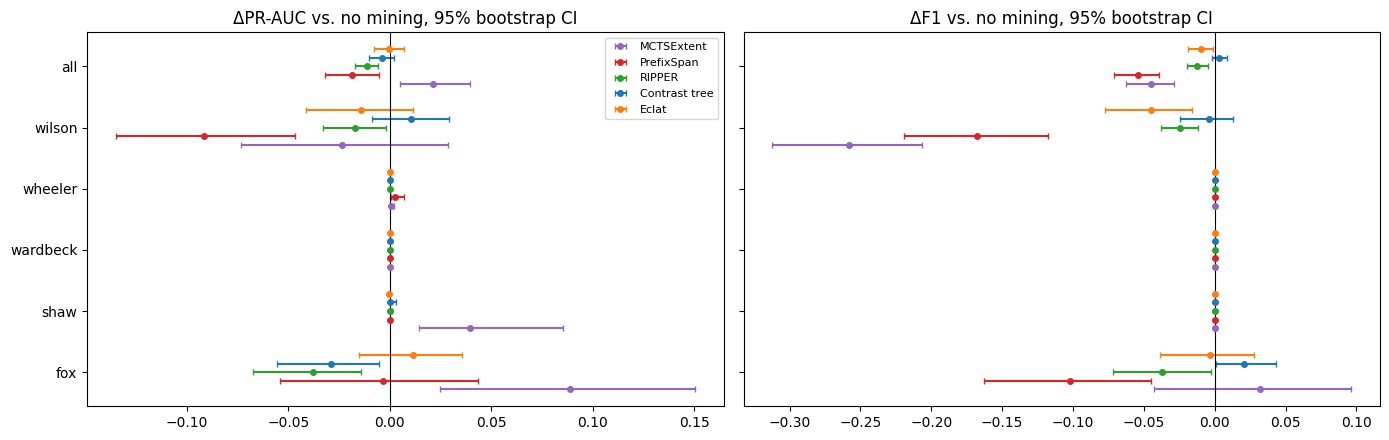

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, metric in zip(axes, ("pr_auc", "f1")):
    for j, a in enumerate(METHODS):
        r = oriented("none", a, metric).reindex(ORDER)
        y = np.arange(len(ORDER)) + (j - 2) * 0.14
        ax.errorbar(r["delta"], y, xerr=[r["delta"] - r["ci_low"], r["ci_high"] - r["delta"]],
                    fmt="o", ms=4, color=COLOR[a], label=LABEL[a], capsize=2)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(np.arange(len(ORDER)), ORDER)
    ax.invert_yaxis()
    ax.set_title(f"Δ{metric.upper().replace('_', '-')} vs. no mining, 95% bootstrap CI")
axes[0].legend(fontsize=8)
plt.tight_layout()

### The paper's contrasts

In [15]:
rows = []
for name, a, b in CONTRASTS:
    for metric in ("pr_auc", "f1"):
        r = oriented(a, b, metric).reindex(ORDER)
        rows.append({"contrast": name, "A → B": f"{LABEL[a]} → {LABEL[b]}", "metric": metric,
                     **{s: cell(r.loc[s]) for s in ORDER}})
boot_contrasts = pd.DataFrame(rows)
boot_contrasts

,contrast,A → B,metric,fox,shaw,wardbeck,wheeler,wilson,all
0,label after → during (atemporal),Eclat → Contrast tree,pr_auc,"-0.040 [-0.080, -0.008] ★","+0.000 [-0.000, +0.003]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, +0.000]","+0.024 [+0.002, +0.046] ★","-0.003 [-0.012, +0.004]"
1,label after → during (atemporal),Eclat → Contrast tree,f1,"+0.024 [-0.010, +0.061]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, -0.000]","-0.000 [-0.000, -0.000]","+0.040 [+0.014, +0.069] ★","+0.013 [+0.004, +0.023] ★"
2,label after → during (temporal),PrefixSpan → MCTSExtent,pr_auc,"+0.092 [+0.043, +0.146] ★","+0.040 [+0.014, +0.085] ★","+0.000 [+0.000, +0.000]","-0.002 [-0.005, -0.000] ★","+0.068 [+0.034, +0.103] ★","+0.040 [+0.028, +0.056] ★"
3,label after → during (temporal),PrefixSpan → MCTSExtent,f1,"+0.134 [+0.059, +0.206] ★","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","-0.090 [-0.128, -0.055] ★","+0.009 [-0.008, +0.025]"
4,two-step → rule set,Contrast tree → RIPPER,pr_auc,"-0.009 [-0.033, +0.014]","+0.000 [-0.002, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [-0.000, +0.000]","-0.028 [-0.046, -0.010] ★","-0.007 [-0.013, -0.001] ★"
5,two-step → rule set,Contrast tree → RIPPER,f1,"-0.058 [-0.089, -0.032] ★","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","-0.020 [-0.038, -0.002] ★","-0.016 [-0.023, -0.009] ★"
6,atemporal → temporal,Eclat → PrefixSpan,pr_auc,"-0.015 [-0.065, +0.032]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.002 [+0.000, +0.007] ★","-0.078 [-0.119, -0.041] ★","-0.018 [-0.031, -0.006] ★"
7,atemporal → temporal,Eclat → PrefixSpan,f1,"-0.099 [-0.165, -0.036] ★","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","-0.123 [-0.167, -0.077] ★","-0.044 [-0.061, -0.030] ★"


In [16]:
tab = vs_none("pr_auc").reset_index().rename(columns={"index": "Method"})
print(to_booktabs(
    tab,
    caption=f"AIT-ADS: ΔPR-AUC over no mining per scenario (70/30 split), with 95\\% paired bootstrap intervals "
            "over test groups (1000 resamples); ★ = interval excludes 0; all = mean over scenarios.",
    label="tab:mining-bootstrap-ait-ads",
))

\begin{table}[t]
\centering
\caption{AIT-ADS: ΔPR-AUC over no mining per scenario (70/30 split), with 95\% paired bootstrap intervals over test groups (1000 resamples); ★ = interval excludes 0; all = mean over scenarios.}
\label{tab:mining-bootstrap-ait-ads}
\begin{tabular}{lllllll}
\toprule
Method & fox & shaw & wardbeck & wheeler & wilson & all \\
\midrule
MCTSExtent & +0.089 [+0.025, +0.150] ★ & +0.040 [+0.014, +0.085] ★ & -0.000 [-0.000, -0.000] & +0.001 [-0.000, +0.002] & -0.024 [-0.073, +0.029] & +0.021 [+0.005, +0.039] ★ \\
PrefixSpan & -0.003 [-0.054, +0.043] & -0.000 [-0.000, -0.000] & -0.000 [-0.000, -0.000] & +0.002 [+0.000, +0.007] ★ & -0.092 [-0.135, -0.047] ★ & -0.019 [-0.032, -0.006] ★ \\
RIPPER & -0.038 [-0.068, -0.014] ★ & +0.000 [-0.000, +0.001] & -0.000 [-0.000, -0.000] & -0.000 [-0.000, +0.000] & -0.017 [-0.033, -0.002] ★ & -0.011 [-0.017, -0.006] ★ \\
Contrast tree & -0.029 [-0.056, -0.005] ★ & -0.000 [-0.000, +0.003] & -0.000 [-0.000, -0.000] & -0.000 [-0.000, +0.

## §6 Seed noise

Std over seeds within a scenario, averaged over scenarios. Eclat, the contrast tree and PrefixSpan are mined once per scenario,
so their spread is the RF seed only; RIPPER and MCTSExtent are re-mined per seed.

In [17]:
seed_sd = (per_step.groupby(["arm", "step_i"])[["pr_auc", "f1", "n_symbolic"]].std()
           .groupby("arm").mean().reindex(ARMS))
seed_sd.columns = [f"{c} seed-sd" for c in seed_sd.columns]
seed_sd

,pr_auc seed-sd,f1 seed-sd,n_symbolic seed-sd
arm,,,
mctsextent,0.021686,0.005626,0.962580
prefixspan,0.003562,0.002572,0.000000
ripper,0.014821,0.010991,1.185123
contrast_tree,0.002810,0.003072,0.000000
eclat,0.002402,0.006128,0.000000
none,0.002192,0.002147,0.000000


## §7 What the features look like

Seed 0 for the stochastic miners. Attack- vs. benign-leaning features per scenario, and the number of conditions
(steps for sequences, items for itemsets and rules).

In [18]:
f0 = features[features["mining_seed"] == features.groupby("arm")["mining_seed"].transform("min")]
lean = (f0.groupby(["arm", "step_i", "source_label"]).size().unstack(fill_value=0)
        .groupby("arm").mean().reindex(METHODS))
lean.columns = [f"{c} / scenario" for c in lean.columns]
cond = (f0.groupby(["arm", "n_conditions"]).size().unstack(fill_value=0)
        .pipe(lambda d: d.div(d.sum(axis=1), axis=0)).reindex(METHODS))
cond.columns = [f"{c} cond." for c in cond.columns]
lean.join(cond).round(3)

,attack / scenario,benign / scenario,1 cond.,2 cond.,3 cond.,4 cond.,5 cond.,6 cond.,7 cond.,8 cond.,9 cond.,10 cond.,11 cond.,13 cond.
arm,,,,,,,,,,,,,,
mctsextent,15.0,25.0,0.315,0.245,0.170,0.060,0.025,0.025,0.03,0.035,0.05,0.03,0.005,0.01
prefixspan,9.4,29.0,0.000,0.219,0.781,0.000,0.000,0.000,0.00,0.000,0.00,0.00,0.000,0.00
ripper,2.0,2.2,0.333,0.524,0.048,0.095,0.000,0.000,0.00,0.000,0.00,0.00,0.000,0.00
contrast_tree,12.2,10.2,0.348,0.518,0.054,0.080,0.000,0.000,0.00,0.000,0.00,0.00,0.000,0.00
eclat,2.0,17.0,0.000,0.063,0.684,0.253,0.000,0.000,0.00,0.000,0.00,0.00,0.000,0.00


### Agreement between scenarios

How many scenarios keep each condition, and the mean pairwise Jaccard of the scenarios' condition sets per method.
Each scenario is mined on its own network, so low agreement is expected; a condition kept in several scenarios is a
pattern that transfers.

In [19]:
sets = f0.groupby(["arm", "step_i"])["condition"].apply(set)
agree = {}
for a in METHODS:
    s = sets.loc[a]
    pairs = [len(s[i] & s[j]) / len(s[i] | s[j]) for i, j in combinations(s.index, 2) if s[i] | s[j]]
    agree[LABEL[a]] = np.mean(pairs) if pairs else np.nan
pd.Series(agree, name="mean pairwise Jaccard of kept conditions between folds").round(3)

MCTSExtent       0.021
PrefixSpan       0.041
RIPPER           0.000
Contrast tree    0.064
Eclat            0.066
Name: mean pairwise Jaccard of kept conditions between folds, dtype: float64

In [20]:
TOP = 6
persist = (f0.groupby(["arm", "condition", "source_label"])["step_i"].nunique()
           .rename("scenarios").reset_index().sort_values(["arm", "scenarios"], ascending=[True, False]))
for a in METHODS:
    print(f"\n== {LABEL[a]} ==")
    top = persist[persist["arm"] == a].head(TOP)
    for _, r in top.iterrows():
        c = r["condition"] if len(r["condition"]) <= 110 else r["condition"][:107] + "..."
        print(f"  {r['scenarios']} scen.  {r['source_label']:<7} {c}")


== MCTSExtent ==
  3 scen.  attack  short:A-Aud-Com4 & short_cat:A-Aud & short_family:audit & short_src:A
  3 scen.  attack  short_src:A
  3 scen.  benign  sig_family:dns
  2 scen.  benign  short:S-Tls-Hnd & short:S-Tls-Rec & short:W-All-Evt & short:W-All-Mul1 & short:W-All-Mul2 & short_cat:S-Tls...
  2 scen.  benign  short:S-Tls-Hnd & short:S-Tls-Rec & short:W-All-Evt & short:W-All-Mul1 & short_cat:S-Tls & short_cat:W-All ...
  2 scen.  benign  short_cat:A-Dns

== PrefixSpan ==
  4 scen.  benign  short_src:W -> short_src:W -> sig_family:tls
  3 scen.  benign  short_src:W -> short_src:W -> short_src:W
  3 scen.  benign  short_src:W -> sig_family:tls -> short_src:W
  2 scen.  benign  short:S-Tls-Hnd -> short:S-Tls-Hnd -> short:W-All-Mul1
  2 scen.  benign  short:W-All-Evt -> short:S-Tls-Hnd -> short_family:dns
  2 scen.  benign  short:W-All-Evt -> short:W-All-Mul1 -> short:W-All-Evt

== RIPPER ==
  1 scen.  attack  NOT_host=inet-dns ∧ short=A-Dns-Clc1
  1 scen.  benign  NOT_host=mail ∧

### Which token levels each method leans on

Share of a method's kept conditions that mention each token level (T2 arm): the full code (`short`, `sig`), the
coarse levels (`short_src`, `short_cat`, `short_family`, `sig_family`) and the other fields (host, alert count, ...).

In [21]:
def token_levels(cond: str) -> set[str]:
    out = set()
    for tok in re.split(r" -> | & | ∧ ", cond):
        tok = tok.strip().removeprefix("NOT_")
        out.add(re.split(r":|<=|>=|<|>|=|_gt_|_le_", tok)[0])
    return out


lv = f0.assign(level=f0["condition"].map(token_levels)).explode("level")
level_share = (lv.groupby(["arm", "level"]).size().div(f0.groupby("arm").size(), level="arm")
               .unstack("arm").reindex(columns=METHODS).fillna(0))
level_share.sort_values("mctsextent", ascending=False).round(3).head(15)

arm,mctsextent,prefixspan,ripper,contrast_tree,eclat
level,,,,,
short_src,0.815,0.328,0.143,0.196,0.347
short,0.800,0.729,0.524,0.259,0.242
short_cat,0.790,0.130,0.143,0.179,0.526
short_family,0.790,0.208,0.000,0.089,0.326
sig_family,0.675,0.193,0.048,0.134,0.242
alert_count,0.000,0.000,0.238,0.134,0.516
host,0.000,0.000,0.524,0.723,0.516
sig,0.000,0.000,0.048,0.116,0.137


## §8 Cost vs. score

Mining time per seed (whole mine → gate → dedupe step, mean over scenarios) against PR-AUC. Log scale on time.

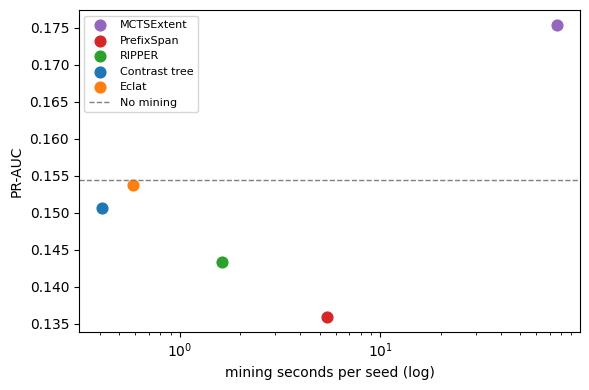

In [22]:
fig, ax = plt.subplots(figsize=(6, 4))
for a in METHODS:
    ax.scatter(main.loc[a, "Mine s"], main.loc[a, "PR-AUC"], s=60, color=COLOR[a], label=LABEL[a])
ax.axhline(main.loc["none", "PR-AUC"], color=COLOR["none"], ls="--", lw=1, label="No mining")
ax.set_xscale("log"); ax.set_xlabel("mining seconds per seed (log)"); ax.set_ylabel("PR-AUC")
ax.legend(fontsize=8); plt.tight_layout()

## §9 Label-noise context

Precision and false positives per day per scenario: every arm flags many benign groups, because the same
alert names occur as attacks inside attack windows and as benign outside them.

In [23]:
ctx = (means.pivot(index="step_i", columns="arm", values="fp_per_day").rename(index=FOLD)[ARMS].round(0)
       .join(folds.set_index("scenario")["test_attack_rate"].round(3)))
ctx.index.name, ctx.columns.name = "scenario", None
ctx

,mctsextent,prefixspan,ripper,contrast_tree,eclat,none,test_attack_rate
scenario,,,,,,,
fox,56.0,60.0,93.0,102.0,90.0,102.0,0.086
shaw,12.0,14.0,11.0,11.0,11.0,16.0,0.040
wardbeck,8.0,19.0,17.0,8.0,18.0,18.0,0.061
wheeler,37.0,60.0,111.0,98.0,89.0,128.0,0.034
wilson,48.0,63.0,144.0,136.0,127.0,159.0,0.062


## Summary (split run `20261121_163159`)

- **Only fox and wilson carry signal.** shaw, wardbeck and wheeler have 14–49 training attacks: every arm scores
  F1 = 0 and PR-AUC at the test attack rate (chance), so they tie every arm and dilute the "all" rows. harrison,
  russellmitchell and santos are skipped (no training attacks), as in thesis Table 5.9. The mean table (§1) is
  dominated by this; read §2 and §5 instead.
- **Mining barely helps on AIT-ADS under this split.** Over no mining (bootstrap, §5), only MCTSExtent gains PR-AUC
  (+0.021 on average, from fox +0.089 and shaw +0.040). RIPPER and PrefixSpan lose PR-AUC significantly; the contrast
  tree and Eclat are within noise on average (the contrast tree loses PR-AUC on fox but gains F1 there).
- **F1 tells a different story for MCTSExtent:** its wilson F1 falls from 0.448 to 0.190 while its PR-AUC holds, so
  its features shift the RF's scores and the fixed 0.5 threshold sits badly there.
- **The contrasts (§5):** label during the search beats label after it for sequences (PrefixSpan → MCTSExtent:
  PR-AUC up on fox, shaw and wilson). For itemsets it's mixed (Eclat → contrast tree: down on fox, up on wilson).
  The rule set loses to the two-step contrast tree on both informative scenarios. Order alone (Eclat → PrefixSpan)
  doesn't help.
- **Tiny significant Δs at chance level** (e.g. wheeler +0.002) are real but meaningless: the bootstrap finds any
  consistent difference, however small, so read the size too.
- **Compared with the earlier LOSO runs:** there MCTSExtent won every fold and every method helped. Under the thesis
  split the gains shrink to one or two scenarios. CSCAS (notebook 06, 20 steps) carries the method comparison;
  AIT-ADS is the second-dataset check, in effect on two scenarios.
